<a href="https://colab.research.google.com/github/rybak97/free_courses/blob/main/Lorenz_Curve_and_Gini_Coefficient.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Based on: https://www.datacamp.com/tutorial/lorenz-curve

# Theory

The Lorenz curve is constructed using two axes. The horizontal axis represents the cumulative percentage of the population, ranked from the poorest to the richest, while the vertical axis shows the cumulative share of the resource being measured, such as income or wealth.

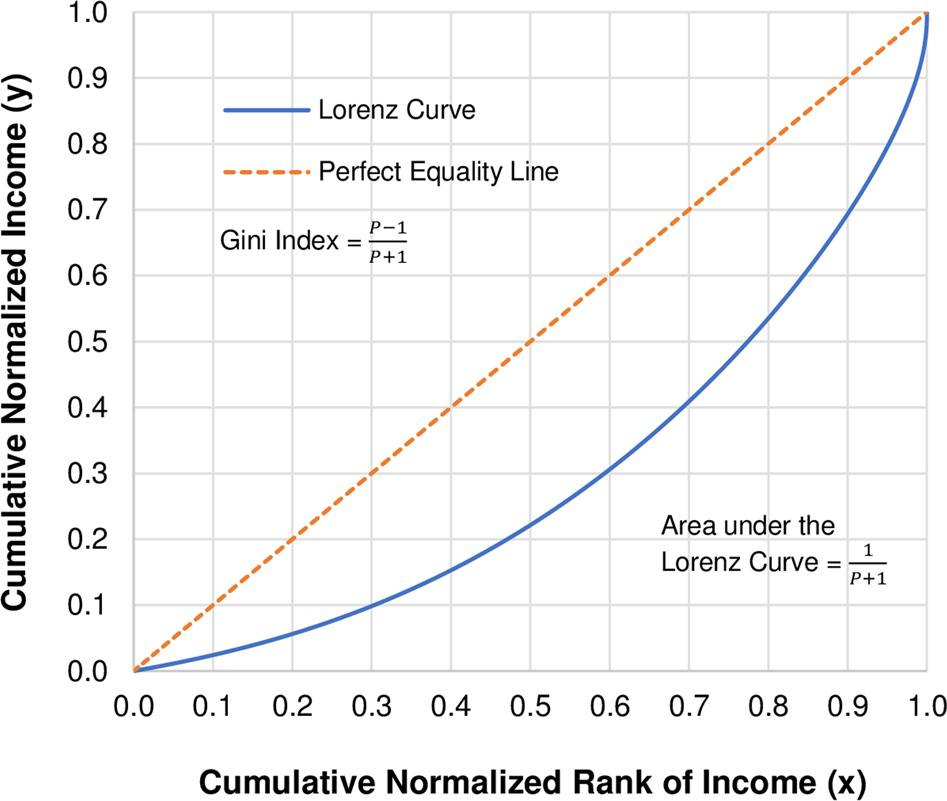

# Example w/ Python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Load the dataset using the corrected URL
url = "https://raw.githubusercontent.com/mmoha110/Urban-Crime-Intelligence/refs/heads/main/data/samples/chicago_crimes.csv"
data = pd.read_csv(url)
display(data.head())

,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,...,ward,community_area,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location
0,14170646,JK220816,2026-04-16T00:00:00.000,034XX W 117TH ST,1242,DECEPTIVE PRACTICE,COMPUTER FRAUD,RESIDENCE,False,False,...,19,74,11,1155525.0,1826811.0,2026,2026-04-23T15:42:27.000,41.680559,-87.706340,"\n, \n(41.680559288, -87.706339549)"
1,14171174,JK222568,2026-04-16T00:00:00.000,001XX N ABERDEEN ST,0810,THEFT,OVER $500,APARTMENT,False,False,...,27,28,06,1169110.0,1901385.0,2026,2026-04-23T15:42:27.000,41.884917,-87.654456,"\n, \n(41.884917254, -87.65445637)"
2,14172242,JK224081,2026-04-16T00:00:00.000,020XX W GIDDINGS ST,1365,CRIMINAL TRESPASS,TO RESIDENCE,RESIDENCE,False,False,...,47,4,26,1162011.0,1931545.0,2026,2026-04-23T15:42:27.000,41.967829,-87.679681,"\n, \n(41.9678294, -87.679680678)"
3,14168420,JK219425,2026-04-16T00:00:00.000,0000X W HUBBARD ST,0460,BATTERY,SIMPLE,STREET,False,False,...,42,8,08B,1176050.0,1903312.0,2026,2026-04-23T15:42:27.000,41.890052,-87.628914,"\n, \n(41.890051565, -87.62891376)"
4,14173513,JK225700,2026-04-16T00:00:00.000,012XX W ROSCOE ST,0710,THEFT,THEFT FROM MOTOR VEHICLE,STREET,False,False,...,44,6,06,1167440.0,1922714.0,2026,2026-04-23T15:42:27.000,41.943481,-87.659974,"\n, \n(41.943481394, -87.659973917)"


In [4]:
# Group by community area and count the number of crimes
crime_counts = data.groupby("community_area").size().reset_index(name="crime_count")

# Drop rows with missing community area values
crime_counts = crime_counts.dropna()

# Sort by crime count
crime_counts = crime_counts.sort_values(by="crime_count").reset_index(drop=True)

# Display the aggregated data
print(crime_counts.head())

   community_area  crime_count
0               9           30
1              47           54
2              12           80
3              74          105
4              37          124


In [5]:
# Calculate cumulative percentages
crime_counts["cumulative_crime"] = crime_counts["crime_count"].cumsum()
crime_counts["cumulative_crime_percentage"] = crime_counts["cumulative_crime"] / crime_counts["crime_count"].sum()
crime_counts["cumulative_population_percentage"] = (np.arange(1, len(crime_counts) + 1)) / len(crime_counts)

# Display the updated data
print(crime_counts.head())

   community_area  crime_count  cumulative_crime  cumulative_crime_percentage  \
0               9           30                30                      0.00060   
1              47           54                84                      0.00168   
2              12           80               164                      0.00328   
3              74          105               269                      0.00538   
4              37          124               393                      0.00786   

   cumulative_population_percentage  
0                          0.012987  
1                          0.025974  
2                          0.038961  
3                          0.051948  
4                          0.064935  


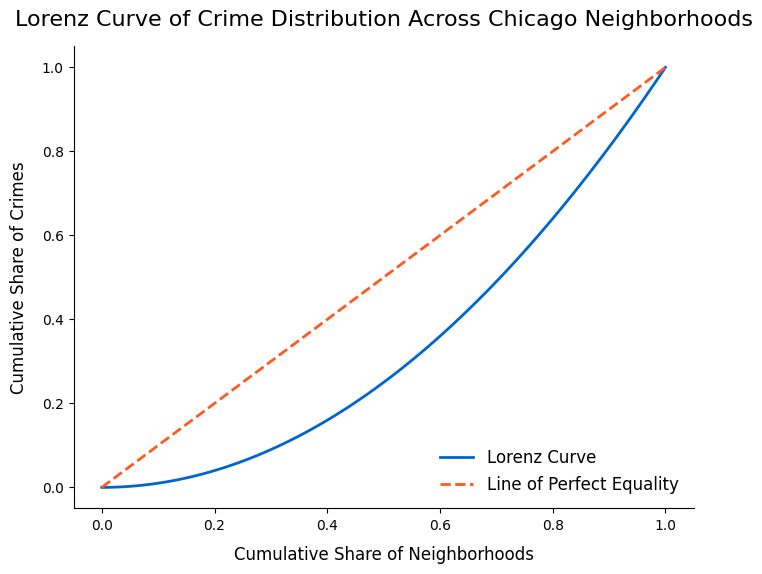

In [6]:
x = np.linspace(0, 1, 100)  # Replace with actual data
y = x**2  # Replace with actual data

# Chicago Bears-inspired colors
blue = "#0065D1"  # Lighter blue for the Lorenz curve
orange = "#FF5A1F"  # Bright orange for the line of perfect equality

# Create the plot
plt.figure(figsize=(8, 6))

# Plot the Lorenz curve
# This curve shows the inequality in crime distribution across neighborhoods
plt.plot(x, y, label="Lorenz Curve", color=blue, linewidth=2)

# Plot the line of perfect equality
# This line represents a hypothetical scenario where crimes are evenly distributed
plt.plot([0, 1], [0, 1], label="Line of Perfect Equality", color=orange, linestyle="--", linewidth=2)

# Add a title to explain what the graph represents
plt.title("Lorenz Curve of Crime Distribution Across Chicago Neighborhoods", fontsize=16, color="black", pad=15)

# Label the x-axis to show what the horizontal axis represents
plt.xlabel("Cumulative Share of Neighborhoods", fontsize=12, color="black", labelpad=10)

# Label the y-axis to show what the vertical axis represents
plt.ylabel("Cumulative Share of Crimes", fontsize=12, color="black", labelpad=10)

# Add a legend to explain the two lines
plt.legend(fontsize=12, loc="lower right", frameon=False)

# Remove the grid for a cleaner look
plt.grid(False)

# Set the background color to white for a professional appearance
plt.gca().set_facecolor("white")

# Remove the top and right borders of the graph for a minimalist design
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

# Save the plot as a PNG file
# This saves the graph as an image file for sharing or embedding in reports
plt.savefig("lorenz_curve_crime.png", dpi=300, bbox_inches="tight")

# Display the plot
plt.show()

It looks like the first 50% of neighborhoods contribute to less than 20% of total crimes, while the remaining neighborhoods bear the bulk of the crime burden.

# Adding Gini Coefficient

The Gini coefficient is a statistical measure used to assess inequality within a dataset. It ranges from 0, representing perfect equality, to 1, indicating perfect inequality. A Gini value of 0 means everyone has an equal share, while 1 means one person owns everything.

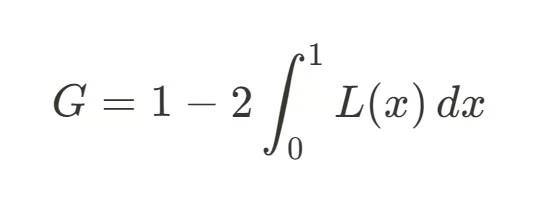

Where:

L(x) is the Lorenz curve,
The integral computes the area under the Lorenz curve.

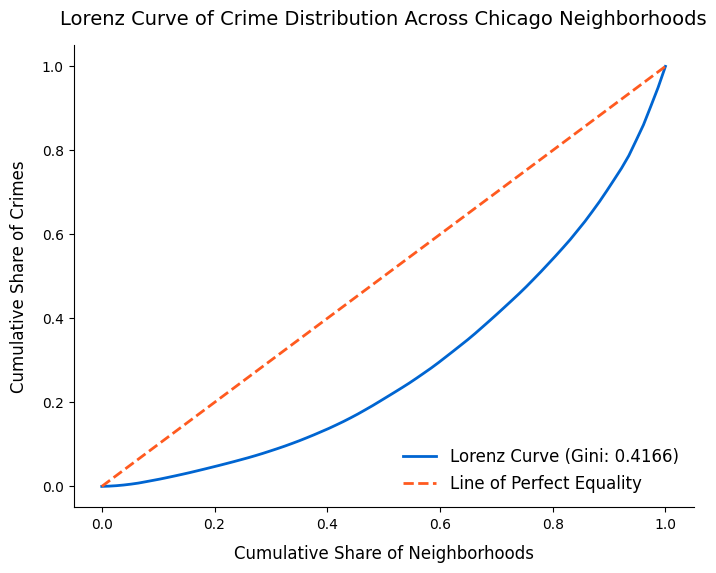

In [10]:
# Rebuild the sorted crime counts DataFrame to ensure we have the required columns
crime_df = data.groupby("community_area").size().reset_index(name="crime_count")
crime_df = crime_df.dropna().sort_values(by="crime_count").reset_index(drop=True)

# Calculate cumulative percentages
crime_df["cumulative_crime"] = crime_df["crime_count"].cumsum()
crime_df["cumulative_crime_percentage"] = crime_df["cumulative_crime"] / crime_df["crime_count"].sum()
crime_df["cumulative_population_percentage"] = np.arange(1, len(crime_df) + 1) / len(crime_df)

# Extract actual cumulative shares
x_real = np.insert(crime_df["cumulative_population_percentage"].values, 0, 0)
y_real = np.insert(crime_df["cumulative_crime_percentage"].values, 0, 0)

# Calculate Gini Coefficient using np.trapezoid (which replaces the deprecated np.trapz in newer NumPy versions)
area_under_lorenz = np.trapezoid(y_real, x_real)
gini_coef = 1 - 2 * area_under_lorenz

# Plot the Lorenz Curve
plt.figure(figsize=(8, 6))

# Plot the Lorenz curve using actual data with Gini coefficient in the label
plt.plot(x_real, y_real, label=f"Lorenz Curve (Gini: {gini_coef:.4f})", color="#0065D1", linewidth=2)

# Plot the line of perfect equality
plt.plot([0, 1], [0, 1], label="Line of Perfect Equality", color="#FF5A1F", linestyle="--", linewidth=2)

# Add details and styling
plt.title("Lorenz Curve of Crime Distribution Across Chicago Neighborhoods", fontsize=14, color="black", pad=15)
plt.xlabel("Cumulative Share of Neighborhoods", fontsize=12, color="black", labelpad=10)
plt.ylabel("Cumulative Share of Crimes", fontsize=12, color="black", labelpad=10)
plt.legend(fontsize=12, loc="lower right", frameon=False)

# Styling details
plt.grid(False)
plt.gca().set_facecolor("white")
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

# Display the plot
plt.show()

Lorenz Curve – Applications:
- Visualizing income and wealth distribution within a population.
- Identifying how unequally resources are distributed.
- Analysing changes in income distribution over time.

---


Gini Coefficient – Applications:
- Measuring the level of income or wealth inequality numerically.
- Comparing inequality levels between countries.
- Monitoring changes in economic inequality over time.
- Evaluating the impact of taxation and redistribution policies.